In [1]:
import tensorflow as tf
import numpy as np

I0000 00:00:1794252317.448015  116622 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794252317.453255  116622 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794252317.857632  116622 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794252319.415755  116622 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.

In [16]:
celsius = np.array([-40, -10, 0, 8, 15, 22,38], dtype=float)
fahrenheit = np.array([-40, 14, 32, 46, 59, 72, 100], dtype=float)

In [17]:
# capa = tf.keras.layers.Dense(units=1, input_shape=[1])
# modelo = tf.keras.Sequential([capa])

capa_oculta1 = tf.keras.layers.Dense(units=3, input_shape=[1])
capa_oculta2 = tf.keras.layers.Dense(units=3)
salida = tf.keras.layers.Dense(units=1)
modelo = tf.keras.Sequential([capa_oculta1, capa_oculta2, salida])

In [18]:
modelo.compile(
    optimizer=tf.keras.optimizers.Adam(0.1),
    loss='mean_squared_error'
)

In [19]:
print("Comenzando a entrenar")
historial = modelo.fit(celsius, fahrenheit, epochs=1000, verbose=False)
print("Modelo entrenado!")

Comenzando a entrenar
Modelo entrenado!


In [ ]:
# Using pip
!pip install tensorflow

# OR using conda (recommended in Anaconda environments)
!conda install tensorflow -y

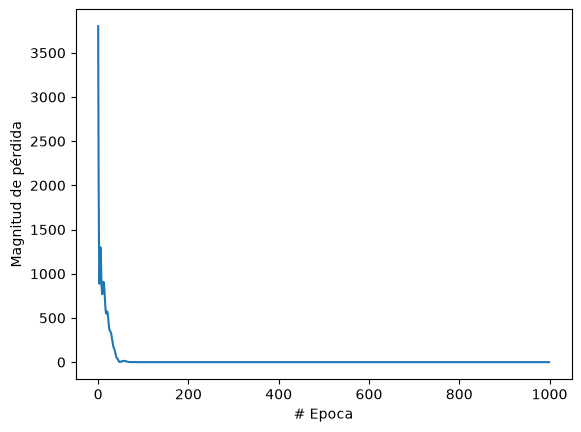

In [20]:
import matplotlib.pyplot as plt
plt.xlabel("# Epoca")
plt.ylabel("Magnitud de pérdida")
plt.plot(historial.history["loss"])
plt.show()

In [21]:
print("Hagamos una predicción!")
resultado = modelo.predict(np.array([100.0], dtype=float))
print("El resultado es " + str(resultado) + " fahrenheit!")

Hagamos una predicción!
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
El resultado es [[211.74744]] fahrenheit!


In [22]:
print("variables internas del modelo")
print(capa_oculta1.get_weights())
print(capa_oculta2.get_weights())
print(salida.get_weights())

variables internas del modelo
[array([[-0.6159705 , -0.28408423,  0.19613096]], dtype=float32), array([-4.4858217 , -0.33554664,  3.9719822 ], dtype=float32)]
[array([[ 0.21313496, -0.3271787 ,  1.173201  ],
       [ 0.12579788, -0.34285682, -0.02599046],
       [ 0.74562925, -0.79686624, -1.4011222 ]], dtype=float32), array([ 0.6118075,  2.350865 , -4.299353 ], dtype=float32)]
[array([[ 0.17189825],
       [ 0.08830186],
       [-1.8068548 ]], dtype=float32), array([4.1248336], dtype=float32)]
